# Actividad del módulo: Regresión lineal múltiple — Advertising.csv

**Objetivo:** pronosticar las ventas (`Sales`) a partir de la inversión en publicidad de
**TV**, **Radio** y **Periódicos (Newspaper)**; dejar en la ecuación final sólo las variables
significativas, calcular un intervalo de confianza del **90 %** y validar los supuestos del modelo.

* División: **70 % entrenamiento / 30 % prueba**, `random_state = 1` (semilla 1).

## 1. Carga de datos y separación entrenamiento/prueba (70/30, semilla 1)

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

import warnings
warnings.filterwarnings("ignore")
import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 54")

df = pd.read_csv('Advertising.csv')
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_tr, X_te, y_tr, y_te = train_test_split(X, y, train_size=0.70, random_state=1)
print(f'Entrenamiento: {X_tr.shape[0]} obs | Prueba: {X_te.shape[0]} obs')

Entrenamiento: 140 obs | Prueba: 60 obs


## 2. Modelo de regresión lineal múltiple y selección de variables significativas

Se ajusta el modelo completo y se aplica **eliminación hacia atrás** (backward elimination):
se elimina la variable con mayor p-valor mientras éste supere α = 0.05.

In [2]:
modelo_full = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
print(modelo_full.summary().tables[1])   # Newspaper tiene p = 0.839 -> NO significativa

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6614      0.368     12.650      0.000       3.933       5.390
TV             0.0550      0.002     32.747      0.000       0.052       0.058
Radio          0.1025      0.010      9.801      0.000       0.082       0.123
Newspaper     -0.0015      0.007     -0.203      0.839      -0.016       0.013


In [3]:
# Ecuación final: sólo TV y Radio (ambas p < 0.001)
X_sel = X_tr[['TV', 'Radio']]
modelo = sm.OLS(y_tr, sm.add_constant(X_sel)).fit()
print(modelo.summary())
# Sales = 4.6390 + 0.0550*TV + 0.1016*Radio

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.898
Method:                 Least Squares   F-statistic:                     612.0
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           4.95e-69
Time:                        12:23:47   Log-Likelihood:                -272.37
No. Observations:                 140   AIC:                             550.7
Df Residuals:                     137   BIC:                             559.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6390      0.350     13.240      0.0

**¿Qué tan bueno es el ajuste?**

* **R² (entrenamiento) = 0.8993**: el modelo explica el **89.9 %** de la variabilidad de las ventas.
* **R² (prueba) = 0.9074**: sobre datos nunca vistos explica el **90.7 %**, lo que indica buena
  capacidad de generalización (sin sobreajuste).
* **RMSE (prueba) ≈ 1.54** unidades de ventas.

In [4]:
y_pred = modelo.predict(sm.add_constant(X_te[['TV', 'Radio']]))
print('R² prueba :', r2_score(y_te, y_pred))
print('RMSE prueba:', np.sqrt(mean_squared_error(y_te, y_pred)))

R² prueba : 0.9073562242286407
RMSE prueba: 1.5376953350310445


## 3. Intervalo de confianza del 90 % para las ventas

Con **TV = 100**, **Radio = 50** (Newspaper ya no pertenece al modelo; se reporta aunque se
pregunte por 70, no afecta la predicción). Se usa `get_prediction` con `alpha = 0.10`:

* **IC 90 % de la media estimada (E[Sales])**: lo que se interpreta como "intervalo de confianza".
* **IC 90 % de predicción** (intervalo para una observación individual): se incluye por completitud.

In [6]:
x_nuevo = pd.DataFrame({'const': [1.0], 'TV': [100.0], 'Radio': [50.0]})
pred = modelo.get_prediction(x_nuevo)
print(pred.summary_frame(alpha=0.10))
# Venta estimada: 15.2217 | IC90 media: [14.7182, 15.7251]
# IC90 predicción individual: [12.3428, 18.1005]

        mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
0  15.221676  0.304019      14.718204      15.725147     12.342813   

   obs_ci_upper  
0     18.100538  


## 4. Validación de supuestos del modelo final (α = 0.10)

| Supuesto | Prueba / herramienta | Estadístico | p-valor | ¿Cumple (90 %)? |
|---|---|---|---|---|
| Linealidad | RESET (F) y corr(residuos, ajustados) | F = 1.12 | 0.291 | **Sí** |
| Normalidad de errores | Jarque-Bera | 24.66 | 4.4e-06 | **No** (colas pesadas, sesgo −0.51) |
| Normalidad de errores | Shapiro-Wilk | W = 0.9696 | 0.0032 | **No** |
| Homocedasticidad | White (LM) | 11.35 | 0.0448 | **No** (evidencia de heterocedasticidad) |
| Homocedasticidad | Breusch-Pagan | 0.0045 | 0.9977 | **Sí** (no se rechaza; BP es menos potente) |
| Independencia | Durbin-Watson | 2.0375 | — (≈2) | **Sí** |
| Multicolinealidad | VIF (TV, Radio) | 1.001 | — (< 10) | **Sí** |

**Interpretación verbal:**

1. **Linealidad:** la prueba RESET (F = 1.12, p = 0.291 > 0.10) y la correlación
   residuos-ajustados ≈ 0 no muestran falta de ajuste; la relación es lineal en TV y Radio.
2. **Normalidad:** con un nivel de confianza del 90 % se **rechaza** la normalidad (JB y Shapiro).
   Los residuos presentan sesgo negativo (−0.51) y curtosis de exceso positiva (1.78): colas más
   pesadas que las de la normal. En muestras moderadas esto infla levemente las probabilidades de
   error tipo I; se recomiendan errores estándar robustos (HC3) para la inferencia.
3. **Homocedasticidad:** la prueba de White (p = 0.0448 < 0.10) sugiere **varianza no constante**,
   aunque Breusch-Pagan (p = 0.998) no la detecta; la prueba de White incluye términos cuadráticos
   y cruzados y es más completa, por lo que se da mayor peso a su evidencia. De nuevo, la
   corrección práctica es usar covarianzas robustas.
4. **Independencia:** Durbin-Watson = 2.04 ≈ 2, sin autocorrelación de primer orden.
5. **Multicolinealidad:** VIF ≈ 1.00 en ambas variables (límite razonable < 10): no hay problema.

In [7]:
resid = modelo.resid
fitted = modelo.fittedvalues

# --- Normalidad (α = 0.10) ---
JB, JBp, skw, krt = sm.stats.jarque_bera(resid)
print('Jarque-Bera:', JB, 'p =', JBp, '| Shapiro:', stats.shapiro(resid))

# --- Homocedasticidad ---
from statsmodels.stats.diagnostic import het_white, het_breuschpagan
print('White:', het_white(resid, modelo.model.exog))
print('Breusch-Pagan:', het_breuschpagan(resid, modelo.model.exog))

# --- Independencia ---
from statsmodels.stats.stattools import durbin_watson
print('Durbin-Watson:', durbin_watson(resid))

# --- Multicolinealidad ---
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xs = sm.add_constant(X_sel)
print([variance_inflation_factor(Xs.values, i) for i in range(1, Xs.shape[1])])

# --- Linealidad (RESET) y correlación residuos-ajustados ---
from statsmodels.stats.diagnostic import linear_reset
print(linear_reset(modelo, power=2, use_f=True))
print('corr(resid, fitted) =', np.corrcoef(resid, fitted)[0, 1])

Jarque-Bera: 24.662861496031102 p = 4.410904674141188e-06 | Shapiro: ShapiroResult(statistic=np.float64(0.9695545971960289), pvalue=np.float64(0.003226973772523572))
White: (np.float64(11.353378151633706), np.float64(0.04480664163871973), np.float64(2.3651653661175973), np.float64(0.04301479079659328))
Breusch-Pagan: (np.float64(0.004532673960611078), np.float64(0.9977362292223558), np.float64(0.0022178444219109915), np.float64(0.9977846490014185))
Durbin-Watson: 2.0375161916374998
[np.float64(1.0013523545176488), np.float64(1.001352354517649)]
<F test: F=1.1215375976393274, p=0.2914649021494157, df_denom=136, df_num=1>
corr(resid, fitted) = 9.976124203160944e-16


## 4.1 Gráficas de diagnóstico de residuos

# Gráfica 1 — Residuos vs valores ajustados (después de "Linealidad")

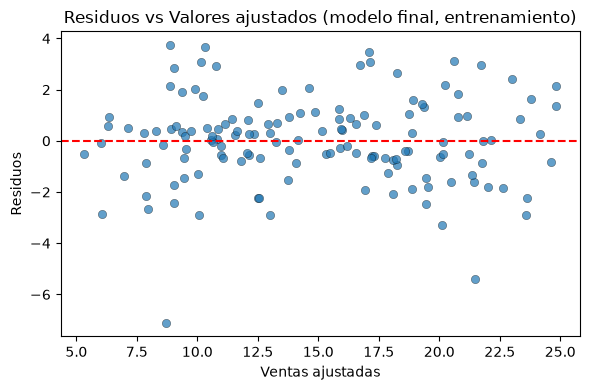

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(fitted, resid, alpha=0.7, edgecolor='k', linewidth=0.3)
ax.axhline(0, color='red', linestyle='--')
ax.set_xlabel('Ventas ajustadas')
ax.set_ylabel('Residuos')
ax.set_title('Residuos vs Valores ajustados (modelo final, entrenamiento)')
plt.tight_layout()
plt.show()

# Gráfica 2 — QQ plot de normalidad (después de "Normalidad")

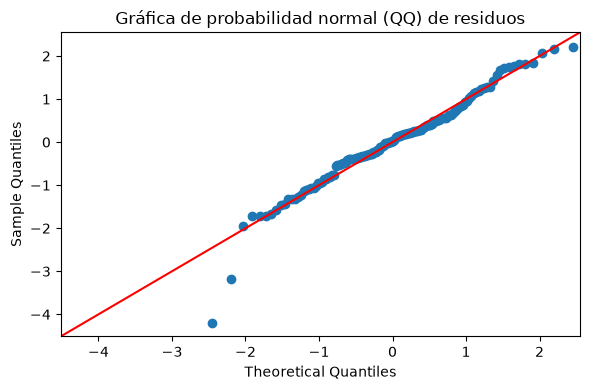

In [10]:
import statsmodels.api as sm

fig, ax = plt.subplots(figsize=(6, 4))
sm.qqplot(resid, line='45', fit=True, ax=ax)
ax.set_title('Gráfica de probabilidad normal (QQ) de residuos')
plt.tight_layout()
plt.show()

# Gráfica 3 — Residuos vs orden de observación (después de "Independencia")

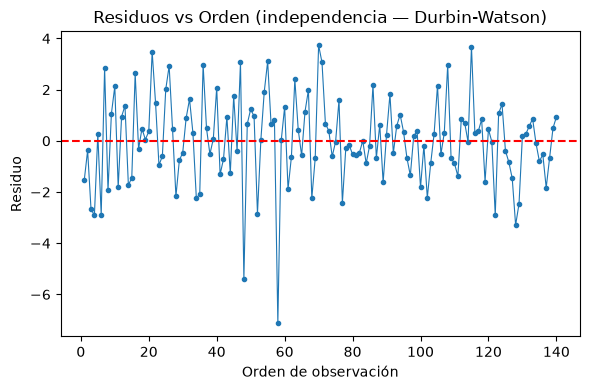

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(resid) + 1), resid, marker='o', markersize=3, linewidth=0.8)
ax.axhline(0, color='red', linestyle='--')
ax.set_xlabel('Orden de observación')
ax.set_ylabel('Residuo')
ax.set_title('Residuos vs Orden (independencia — Durbin-Watson)')
plt.tight_layout()
plt.show()

# Gráfica 4 — Histograma de residuos vs curva normal (también en "Normalidad")

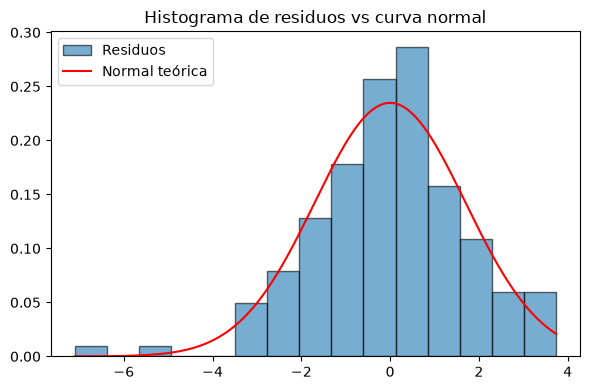

In [12]:
import numpy as np
from scipy import stats

fig, ax = plt.subplots(figsize=(6, 4))
xs = np.linspace(resid.min(), resid.max(), 300)
ax.hist(resid, bins=15, density=True, alpha=0.6, edgecolor='k', label='Residuos')
ax.plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), 'r-', label='Normal teórica')
ax.set_title('Histograma de residuos vs curva normal')
ax.legend()
plt.tight_layout()
plt.show()

# Gráfica 5 — Pronóstico vs real en el grupo de prueba (mejor al final del Paso 2)

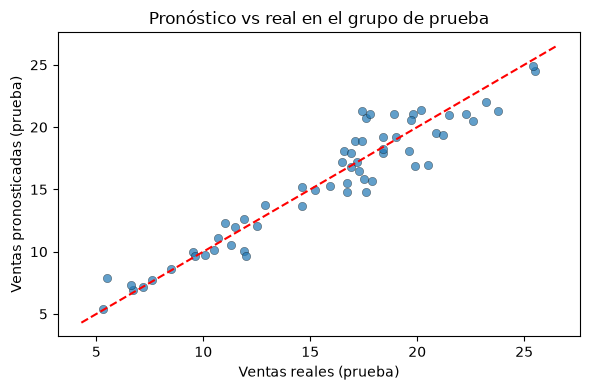

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(y_te, y_pred, alpha=0.7, edgecolor='k', linewidth=0.3)
lim = [min(y_te.min(), y_pred.min()) - 1, max(y_te.max(), y_pred.max()) + 1]
ax.plot(lim, lim, 'r--')
ax.set_xlabel('Ventas reales (prueba)')
ax.set_ylabel('Ventas pronosticadas (prueba)')
ax.set_title('Pronóstico vs real en el grupo de prueba')
plt.tight_layout()
plt.show()

## 5. Verificación: fórmulas propias vs librerías

Se programan desde cero el **sesgo**, la **curtosis**, el **estadístico de Durbin-Watson** y la
**prueba de White** (regresión auxiliar de e² sobre [1, X, X², X·X]; LM = n·R² ~ χ²).
Las diferencias con `scipy.stats.skew`, `scipy.stats.kurtosis`,
`statsmodels.durbin_watson` y `statsmodels.het_white` son del orden de 1e-14 o menores
(sólo error de redondeo de punto flotante).

In [8]:
def mi_sesgo(x):
    x = np.asarray(x, float); x = x - x.mean()
    return np.mean(x**3) / np.mean(x**2)**1.5

def mi_curtosis_exceso(x):
    x = np.asarray(x, float); x = x - x.mean()
    return np.mean(x**4) / np.mean(x**2)**2 - 3

def mi_durbin_watson(e):
    e = np.asarray(e, float)
    return np.sum(np.diff(e)**2) / np.sum(e**2)

def mi_white(e, X):
    e = np.asarray(e, float); X = np.asarray(X, float)
    n, k = X.shape
    cols = [np.ones(n)] + [X[:, j] for j in range(k)] + [X[:, j]**2 for j in range(k)]
    cols += [X[:, i]*X[:, j] for i in range(k) for j in range(i+1, k)]
    aux = sm.OLS(e**2, np.column_stack(cols)).fit()
    LM = n * aux.rsquared
    return LM, 1 - stats.chi2.cdf(LM, np.column_stack(cols).shape[1] - 1)

print('Sesgo     propio/librería :', mi_sesgo(resid), '/', stats.skew(resid, bias=True))
print('Curtosis  propio/librería :', mi_curtosis_exceso(resid), '/',
      stats.kurtosis(resid, fisher=True, bias=True))
print('Durbin-W  propio/librería :', mi_durbin_watson(resid), '/', durbin_watson(resid))
print('White     propio/librería :', mi_white(resid, X_sel.values), '/',
      het_white(resid, modelo.model.exog)[:2])

Sesgo     propio/librería : -0.5124182186793589 / -0.5124182186793589
Curtosis  propio/librería : 1.7825906401266733 / 1.7825906401266733
Durbin-W  propio/librería : 2.0375161916374998 / 2.0375161916374998
White     propio/librería : (np.float64(11.353378151633692), np.float64(0.044806641638719946)) / (np.float64(11.353378151633706), np.float64(0.04480664163871973))
